# EDA

Flashlights from knivesandtools.com, 200 products.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from load import FLAGS, NUMERIC, load

sns.set_theme(style="whitegrid")
df = load()
df.head()

,url,name,price,brand,colour,length_cm,weight_g,material,lumens,rechargeable,tactical,edc
0,https://www.knivesandtools.com/en/pt/-nitecore...,"Nitecore EDC37 Ultimate Tactical, rechargeable...",139.95,Nitecore,[black],10.80,200.0,"[aluminum, carbon fiber, composite]",8000.0,True,True,True
1,https://www.knivesandtools.com/en/pt/-fenix-e1...,Fenix E18R rechargeable LED-flashlight,59.95,Fenix,[black],6.70,36.0,[aluminum],1200.0,True,False,False
2,https://www.knivesandtools.com/en/pt/-led-lens...,Ledlenser M7R.2,136.99,Ledlenser,[black],15.10,206.0,[aluminum],400.0,False,False,False
3,https://www.knivesandtools.com/en/pt/-nitecore...,"Nitecore P20iX tactical flashlight, 4000 lumens",149.95,Nitecore,[black],14.15,116.0,[aluminum],4000.0,False,True,False
4,https://www.knivesandtools.com/en/pt/-maglite-...,Maglite - torch 5-D type,58.99,Maglite,[black],43.40,596.0,[aluminum],151.0,False,False,False


## 1. Overview

In [2]:
hashable = df.map(lambda v: tuple(v) if isinstance(v, list) else v)
pd.DataFrame(
    {
        "type": df.dtypes.astype(str),
        "non-null": df.notna().sum(),
        "unique": hashable.nunique(),
    }
)

,type,non-null,unique
url,str,200,200
name,str,200,200
price,float64,200,129
brand,category,200,7
colour,object,200,22
length_cm,float64,194,96
weight_g,float64,199,106
material,object,196,11
lumens,float64,197,74
rechargeable,bool,200,2


In [3]:
df[NUMERIC].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
price,200.0,106.2,86.5,17.0,57.0,80.0,120.1,581.0
length_cm,194.0,14.4,5.3,3.5,12.1,14.0,15.5,43.4
weight_g,199.0,188.1,227.5,24.0,72.0,126.0,203.0,1636.0
lumens,197.0,2336.7,3385.7,9.0,400.0,1200.0,3000.0,21000.0


In [4]:
df["brand"].value_counts().to_frame()

,count
brand,
Fenix,62
Nitecore,45
Maglite,31
Ledlenser,25
Wuben,25
Streamlight,11
HDS systems,1


In [5]:
df["colour"].explode().value_counts().to_frame()

,count
colour,
black,155
grey,11
green,10
blue,7
red,6
silver,5
white,5
purple,3
orange,3


In [6]:
df["material"].explode().value_counts().to_frame()

,count
material,
aluminum,170
plastic,17
polycarbonate,7
stainless steel,6
composite,5
rubber,4
carbon fiber,3
polymer,2
nylon,1


In [7]:
df[FLAGS].sum().to_frame("products")

,products
rechargeable,106
tactical,37
edc,35


## 2. Distributions

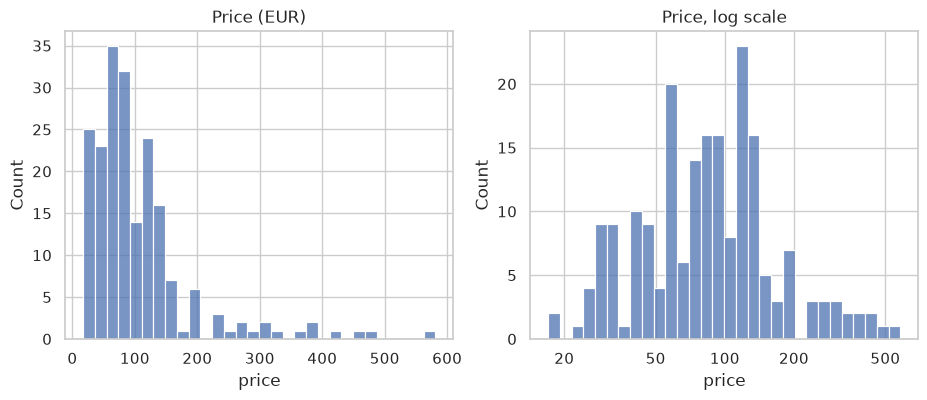

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["price"], bins=30, ax=axes[0])
sns.histplot(df["price"], bins=30, log_scale=True, ax=axes[1])
axes[0].set_title("Price (EUR)")
axes[1].set_title("Price, log scale")
axes[1].set_xticks([20, 50, 100, 200, 500])
axes[1].xaxis.set_major_formatter("{x:g}")
axes[1].xaxis.set_minor_formatter("")
plt.show()

*Price is right-skewed, the log scale is closer to symmetric.*

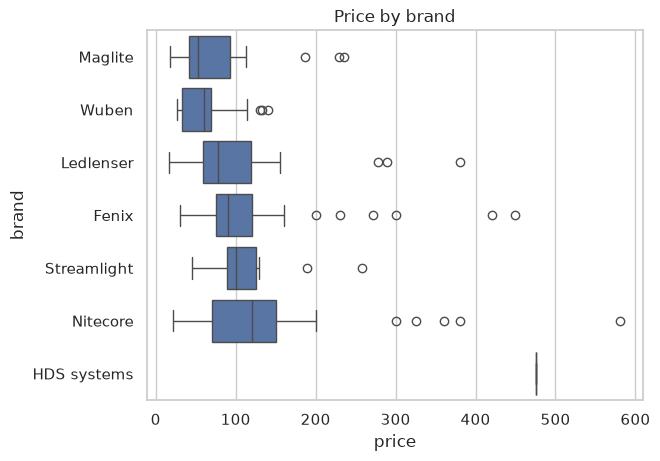

In [9]:
order = df.groupby("brand", observed=True)["price"].median().sort_values().index
sns.boxplot(df, x="price", y="brand", order=order)
plt.title("Price by brand")
plt.show()

*Fenix and Nitecore have the widest price ranges, Maglite is concentrated at the lower end.*

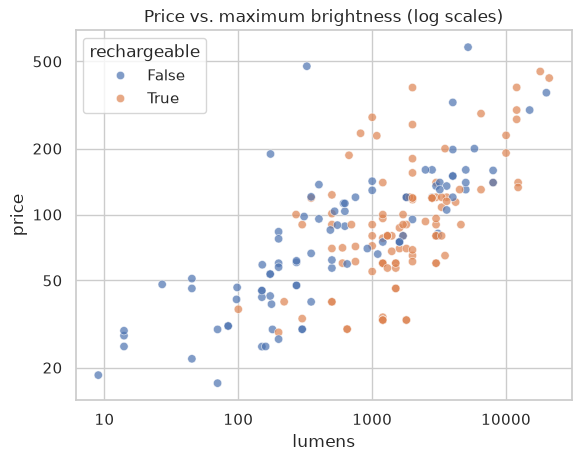

In [10]:
ax = sns.scatterplot(df, x="lumens", y="price", hue="rechargeable", alpha=0.7)
ax.set(xscale="log", yscale="log", title="Price vs. maximum brightness (log scales)")
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter("{x:g}")
    axis.set_minor_formatter("")
ax.set_yticks([20, 50, 100, 200, 500])
plt.show()

*Brighter products tend to be more expensive, rechargeables sit slightly higher at the same brightness.*

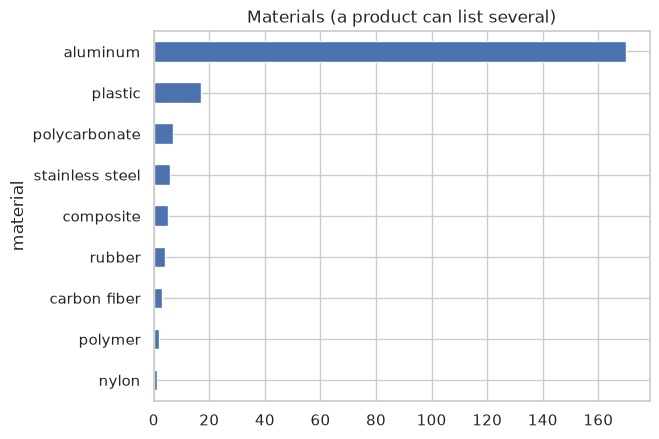

In [11]:
df["material"].explode().value_counts().plot.barh()
plt.gca().invert_yaxis()
plt.title("Materials (a product can list several)")
plt.show()

*Aluminum dominates, most other materials appear only a few times.*

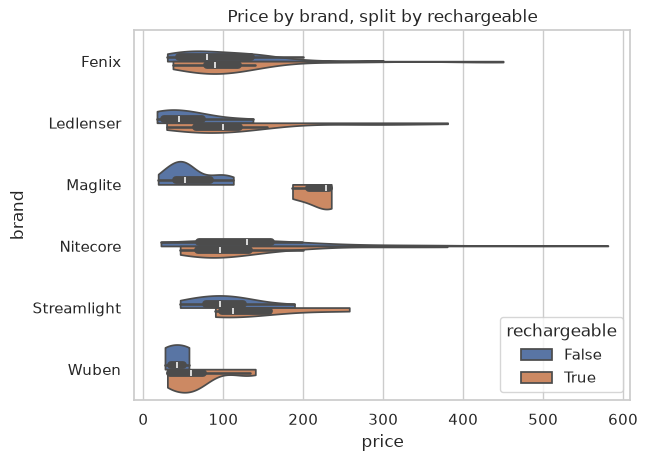

In [12]:
counts = df["brand"].value_counts()
main_brands = df[df["brand"].isin(counts[counts > 1].index)].copy()
main_brands["brand"] = main_brands["brand"].cat.remove_unused_categories()
sns.violinplot(main_brands, x="price", y="brand", hue="rechargeable", split=True, cut=0)
plt.title("Price by brand, split by rechargeable")
plt.show()

*Rechargeability changes the price distribution mainly for Fenix and Nitecore.*

## 3. Outliers

IQR rule (1.5 × IQR) and z-score (|z| > 3).

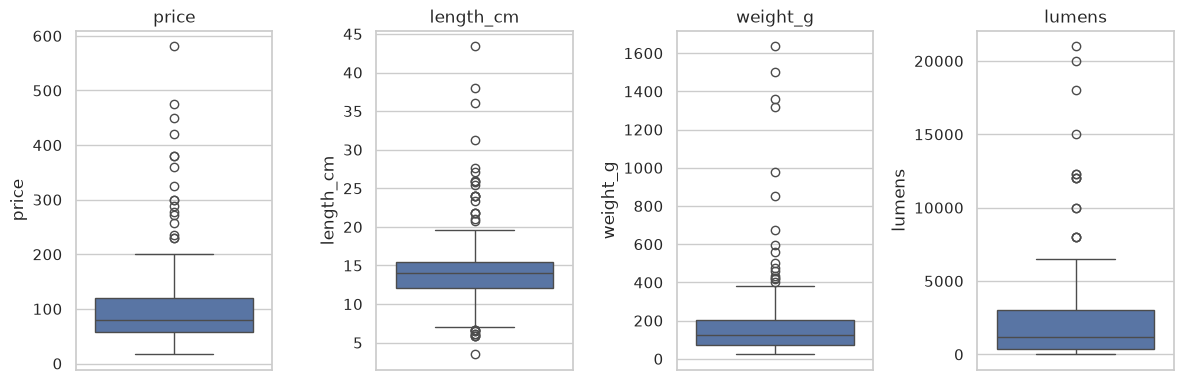

In [13]:
fig, axes = plt.subplots(1, len(NUMERIC), figsize=(12, 4))
for ax, column in zip(axes, NUMERIC):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(column)
fig.tight_layout()
plt.show()

*All numeric attributes have values above the upper whisker, these are the outliers analysed below.*

In [14]:
num = df[NUMERIC]
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
iqr_outliers = (num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)
z_outliers = ((num - num.mean()) / num.std()).abs() > 3

pd.DataFrame({"IQR": iqr_outliers.sum(), "z-score": z_outliers.sum()})

,IQR,z-score
price,17,6
length_cm,31,4
weight_g,16,5
lumens,14,4


In [15]:
df.loc[z_outliers.any(axis=1), ["name", *NUMERIC]]

,name,price,length_cm,weight_g,lumens
4,Maglite - torch 5-D type,58.99,43.4,596.0,151.0
31,"HDS systems EDC Custom LED-flashlight, 325 lum...",475.53,9.8,105.0,325.0
32,"Fenix LR60R rechargeable searchlight, 21000 lu...",419.99,20.7,1500.0,21000.0
102,"Fenix LR80R rechargeable LED flashlight, 18000...",449.95,25.9,1636.0,18000.0
112,"Ledlenser P21R rechargeable flashlight, 12000 ...",380.49,38.0,1320.0,12000.0
119,"Fenix LR50R rechargeable LED flashlight, 12000...",272.00,16.3,980.0,12000.0
126,"Nitecore TM20K, 20.000 lumen, tactical flashlight",359.95,NaN,422.0,20000.0
161,"Fenix LR40R V2.0 powerful LED flashlight, 1500...",299.95,NaN,850.0,15000.0
168,"Maglite flashlight type 4 D-cell, black",46.49,36.0,474.0,98.0
186,"Nitecore P40, rechargeable LEP torch, 2000 lumens",379.95,18.6,400.0,2000.0


## 4. Missing values

In [16]:
missing = df.isna().sum()
print(f"Total missing values: {missing.sum()}")
missing[missing > 0].to_frame("missing")

Total missing values: 14


,missing
length_cm,6
weight_g,1
material,4
lumens,3


In [17]:
per_product = df.isna().sum(axis=1)
per_product.value_counts().sort_index().to_frame("products")

,products
0,189
1,9
2,1
3,1


In [18]:
with_gaps = missing[missing > 0].index
df.loc[per_product > 1, ["name", *with_gaps]]

,name,length_cm,weight_g,material,lumens
126,"Nitecore TM20K, 20.000 lumen, tactical flashlight",NaN,422.0,None,20000.0
154,Nitecore 21700 Intelligent Battery System batt...,NaN,124.0,None,NaN


## 5. Correlation

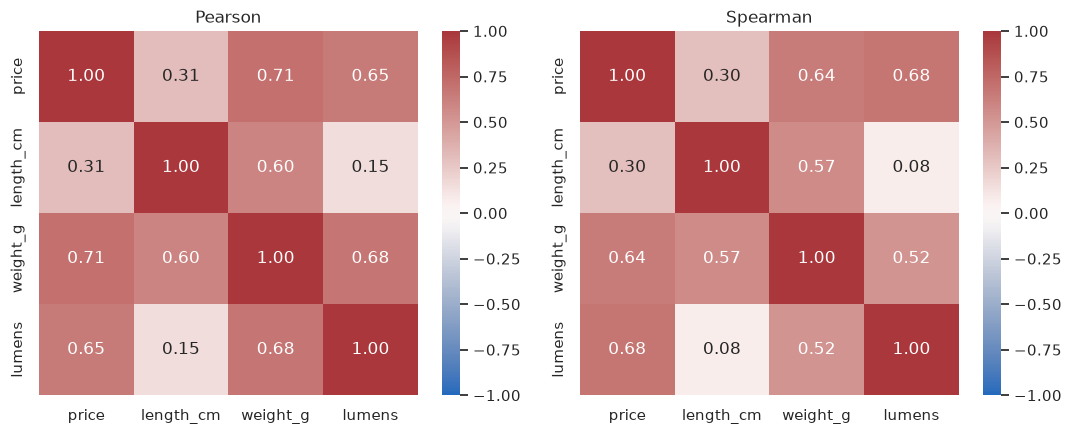

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[NUMERIC].corr(method)
    sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax)
    ax.set_title(method.capitalize())
fig.tight_layout()
plt.show()

*Weight and brightness are the strongest correlates of price, length is weaker.*